# Case 1: The tree that aced practice

**Applies** chapter 1 (Overfitting; bias and variance through learning curves), chapter 2
(Regularisation, the depth brake) and chapter 4 (Trees, used and compared).

**The ticket.** A Portuguese bank phoned 41,188 customers about a term deposit (UCI Bank Marketing,
public data). Kalpa's Marketing team is copying the method for its own nudge: Anand's budget covers
one campaign, so a model that shines on last quarter's customers and fails on next quarter's burns
the whole budget. A teammate grew a decision tree with no depth limit and posted its training score.

**By the end you can** score a model on rows it has never seen, put the score beside the do-nothing
baseline, draw the depth curve, and read three pairs of learning curves.

**Search for:** overfitting decision tree, max_depth, learning curve scikit-learn, bias variance tradeoff.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11, "axes.titleweight": "bold"})
INK, VIOLET, ROSE, GREEN, MUTED = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690"

def check(label, ok):
    """Print PASS or FAIL on one line, so a reader sees at a glance whether a step worked."""
    print(("PASS  " if ok else "FAIL  ") + label)

print("Charts and the check() helper are ready.")

Charts and the check() helper are ready.


In [2]:
# Load the day's public dataset once; later runs read the cached copy.
import io, zipfile, pathlib, urllib.request
import pandas as pd
CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)

def fetch(url, name):
    path = CACHE / name
    if not path.exists():
        path.write_bytes(urllib.request.urlopen(url, timeout=60).read())
    return path

def load_bank():
    """UCI Bank Marketing, bank-additional-full.csv (CC BY 4.0). The zip holds a second zip."""
    f = CACHE / "bank-additional-full.csv"
    if not f.exists():
        outer = zipfile.ZipFile(fetch("https://archive.ics.uci.edu/static/public/222/bank+marketing.zip",
                                      "bank+marketing.zip"))
        inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
        f.write_bytes(inner.read("bank-additional/bank-additional-full.csv"))
    return pd.read_csv(f, sep=";")

bank = load_bank()
print(f"{len(bank):,} calls, {bank.shape[1]} columns, {bank['y'].eq('yes').mean():.2%} said yes")

41,188 calls, 21 columns, 11.27% said yes


## Step 1: Rebuild Wednesday's honest feature set and the week's split

The customer table, the economy columns and the never-contacted flag; `duration` stays out because it
is written after the call ends. The test slice stays sealed in the envelope until Friday.

In [3]:
# The week's pipeline: the same columns, the same split and the same baseline every day.
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, accuracy_score

PROFILE = ["age", "job", "marital", "education", "default", "housing", "loan"]
HISTORY = ["contact", "month", "day_of_week", "campaign", "previous", "poutcome"]
ECONOMY = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

def engineer(df):
    """Wednesday's fix for pdays: 999 means never contacted, so it becomes a flag plus the real days."""
    df = df.copy()
    df["never_contacted"] = (df["pdays"] == 999).astype(int)
    df["days_since_contact"] = np.where(df["pdays"] == 999, 0, df["pdays"])
    return df

# Wednesday's honest feature set: the customer table, the economy, the pdays flag. No duration.
HONEST = PROFILE + HISTORY + ECONOMY + ["never_contacted", "days_since_contact"]

def week_split(df, seed=42):
    """Test is sealed first (20 percent, the envelope); the rest splits 75/25 into train and validation."""
    y = (df["y"] == "yes").astype(int)
    rest, test = train_test_split(df.index, test_size=0.20, stratify=y, random_state=seed)
    train, val = train_test_split(rest, test_size=0.25, stratify=y.loc[rest], random_state=seed)
    return df.loc[train], df.loc[val], df.loc[test]

bank = engineer(bank)
train, val, test = week_split(bank)          # test stays in the sealed envelope until Friday
X_train, X_val = train[HONEST], val[HONEST]
y_train = (train["y"] == "yes").astype(int)
y_val = (val["y"] == "yes").astype(int)

# pandas 3 reads text as the "str" dtype, so test for numbers rather than for object.
NUM = [c for c in HONEST if pd.api.types.is_numeric_dtype(bank[c])]
CAT = [c for c in HONEST if c not in NUM]

def prep(scale=True):
    """One-hot the categories; scale the numbers for the linear model (trees do not need it)."""
    return ColumnTransformer([("num", StandardScaler() if scale else "passthrough", NUM),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])

print(f"train {len(train):,}  validation {len(val):,}  test {len(test):,} (sealed)")
print(f"{len(NUM)} number columns and {len(CAT)} category columns")

train 24,712  validation 8,238  test 8,238 (sealed)
10 number columns and 10 category columns


In [4]:
check("41,188 calls loaded", len(bank) == 41188)
check("train, validation and test hold 24,712, 8,238 and 8,238 rows",
      (len(train), len(val), len(test)) == (24712, 8238, 8238))

PASS  41,188 calls loaded
PASS  train, validation and test hold 24,712, 8,238 and 8,238 rows


## Step 2: What does doing nothing score?

Any model has to beat the rule "call nobody". It is right for every customer who would have said no.

In [5]:
baseline_acc = 1 - y_val.mean()
print(f"Call nobody: right for {baseline_acc:.1%} of validation customers "
      f"({(y_val == 0).sum():,} of {len(y_val):,})")

Call nobody: right for 88.7% of validation customers (7,310 of 8,238)


## Step 3: Predict, then grow the tree with no limit

Write down two numbers before you run the cell: the tree's accuracy on the 24,712 customers it learned
from, and on the 8,238 validation customers it has never seen.

In [6]:
tree_free = Pipeline([("prep", prep(scale=False)),
                      ("model", DecisionTreeClassifier(random_state=42))])   # no depth limit
tree_free.fit(X_train, y_train)

train_acc = accuracy_score(y_train, tree_free.predict(X_train))
val_acc = accuracy_score(y_val, tree_free.predict(X_val))
leaves = tree_free.named_steps["model"].get_n_leaves()
depth = tree_free.named_steps["model"].get_depth()
print(f"Training accuracy   {train_acc:.1%}")
print(f"Validation accuracy {val_acc:.1%}")
print(f"Call nobody         {baseline_acc:.1%}")
print(f"The tree is {depth} questions deep with {leaves:,} leaves: "
      f"one leaf for every {len(X_train) / leaves:.1f} training customers")

Training accuracy   99.6%
Validation accuracy 84.1%
Call nobody         88.7%
The tree is 37 questions deep with 3,662 leaves: one leaf for every 6.7 training customers


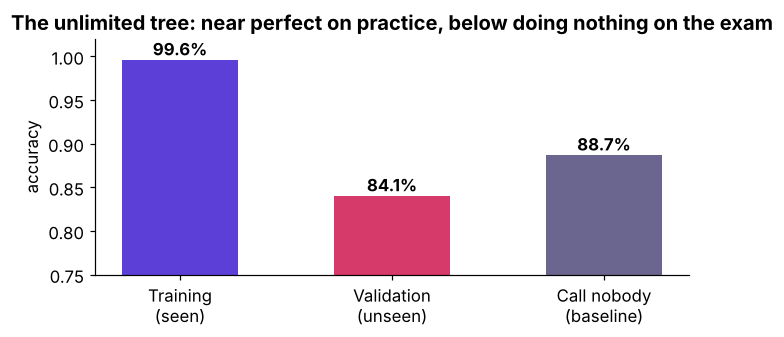

In [7]:
fig, ax = plt.subplots(figsize=(6.4, 3.2))
names = ["Training\n(seen)", "Validation\n(unseen)", "Call nobody\n(baseline)"]
vals = [train_acc, val_acc, baseline_acc]
bars = ax.bar(names, vals, color=[VIOLET, ROSE, MUTED], width=0.55)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.005, f"{v:.1%}", ha="center", fontweight="bold")
ax.set_ylim(0.75, 1.02); ax.set_ylabel("accuracy")
ax.set_title("The unlimited tree: near perfect on practice, below doing nothing on the exam")
plt.tight_layout(); plt.show()

In [8]:
check("the unlimited tree scores above 99 percent on its own training rows", train_acc > 0.99)
check("on unseen customers it falls below the call-nobody baseline", val_acc < baseline_acc)

PASS  the unlimited tree scores above 99 percent on its own training rows
PASS  on unseen customers it falls below the call-nobody baseline


## Step 4: What did the tree memorise?

A leaf is a final answer. If most leaves hold one or two customers, the tree has written down
individual customers rather than a pattern that will hold for next quarter's.

In [9]:
leaf_id = tree_free.named_steps["model"].apply(tree_free.named_steps["prep"].transform(X_train))
sizes = pd.Series(leaf_id).value_counts()
small = (sizes <= 2).sum()
print(f"{small:,} of {leaves:,} leaves ({small / leaves:.0%}) hold one or two customers")
print("Customers per leaf, the commonest sizes:")
print(sizes.value_counts().sort_index().head(6).rename("leaves").to_string())

2,323 of 3,662 leaves (63%) hold one or two customers
Customers per leaf, the commonest sizes:
count
1    1709
2     614
3     297
4     179
5     117
6      84


## Step 5: Turn the brake one notch at a time: the depth curve

Same data, same split; only `max_depth` changes. Error is the share of customers the model gets
wrong (1 minus accuracy), so lower is better and the baseline sits at 11.3 percent.

In [10]:
depths = [1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 15, 20, 25, 30, None]
rows = []
for d in depths:
    m = Pipeline([("prep", prep(scale=False)),
                  ("model", DecisionTreeClassifier(max_depth=d, random_state=42))]).fit(X_train, y_train)
    rows.append({"max_depth": d if d else "none",
                 "train_error": 1 - accuracy_score(y_train, m.predict(X_train)),
                 "val_error": 1 - accuracy_score(y_val, m.predict(X_val)),
                 "val_auc": roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])})
curve = pd.DataFrame(rows)
print(curve.round(4).to_string(index=False))

max_depth  train_error  val_error  val_auc
        1       0.1127     0.1126   0.6990
        2       0.1010     0.1010   0.7443
        3       0.1006     0.1005   0.7511
        4       0.1000     0.1008   0.7570
        5       0.0989     0.1025   0.7809
        6       0.0950     0.1010   0.7804
        7       0.0925     0.1018   0.7812
        8       0.0883     0.1021   0.7717
       10       0.0794     0.1082   0.7329
       12       0.0694     0.1116   0.6904
       15       0.0533     0.1179   0.6077
       20       0.0297     0.1366   0.6099
       25       0.0127     0.1500   0.6164
       30       0.0058     0.1578   0.6181
     none       0.0036     0.1594   0.6221


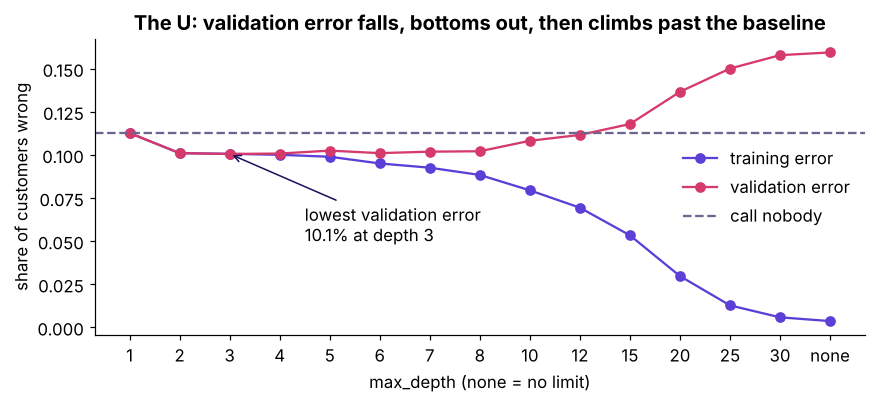

In [11]:
x = range(len(curve))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(x, curve["train_error"], "o-", color=VIOLET, label="training error")
ax.plot(x, curve["val_error"], "o-", color=ROSE, label="validation error")
ax.axhline(1 - baseline_acc, color=MUTED, ls="--", label="call nobody")
best = curve["val_error"].idxmin()
ax.annotate(f"lowest validation error\n{curve.loc[best, 'val_error']:.1%} at depth {curve.loc[best, 'max_depth']}",
            (best, curve.loc[best, "val_error"]), xytext=(best + 1.5, 0.05),
            arrowprops=dict(arrowstyle="->", color=INK))
ax.set_xticks(list(x)); ax.set_xticklabels(curve["max_depth"].astype(str))
ax.set_xlabel("max_depth (none = no limit)"); ax.set_ylabel("share of customers wrong")
ax.set_title("The U: validation error falls, bottoms out, then climbs past the baseline")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

In [12]:
check("the best depth beats the call-nobody baseline on validation",
      curve["val_error"].min() < 1 - baseline_acc)
check("the unlimited tree has the widest train-validation gap of all depths",
      (curve["val_error"] - curve["train_error"]).idxmax() == len(curve) - 1)

PASS  the best depth beats the call-nobody baseline on validation
PASS  the unlimited tree has the widest train-validation gap of all depths


## Step 6: Learning curves: which side of the trade does each tree sit on?

A learning curve trains on more and more customers and plots two errors: on the rows it learned from
and on rows held out (five-fold cross-validation, chapter 3). Three trees: a stump (one question), the
unlimited tree, and a tree braked at depth 6 with at least 50 customers per leaf.

In [13]:
from sklearn.model_selection import learning_curve, StratifiedKFold
folds = StratifiedKFold(5, shuffle=True, random_state=42)
trees = {"Stump (depth 1)": DecisionTreeClassifier(max_depth=1, random_state=42),
         "No limit": DecisionTreeClassifier(random_state=42),
         "Depth 6, leaf 50": DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=42)}
lc = {}
for name, model in trees.items():
    sizes_, tr, va = learning_curve(Pipeline([("prep", prep(scale=False)), ("model", model)]),
                                    X_train, y_train, cv=folds, scoring="accuracy",
                                    train_sizes=[0.05, 0.1, 0.25, 0.5, 0.75, 1.0])
    lc[name] = (sizes_, 1 - tr.mean(axis=1), 1 - va.mean(axis=1))
    print(f"{name:18s} at {sizes_[-1]:,} rows: training error {lc[name][1][-1]:.3f}, "
          f"held-out error {lc[name][2][-1]:.3f}, gap {lc[name][2][-1] - lc[name][1][-1]:.3f}")

Stump (depth 1)    at 19,769 rows: training error 0.113, held-out error 0.113, gap -0.000


No limit           at 19,769 rows: training error 0.003, held-out error 0.165, gap 0.162


Depth 6, leaf 50   at 19,769 rows: training error 0.098, held-out error 0.101, gap 0.002


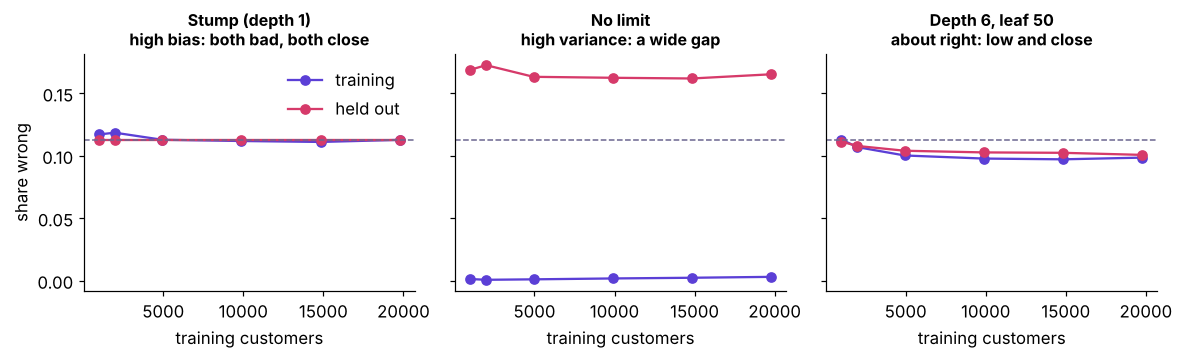

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
verdict = {"Stump (depth 1)": "high bias: both bad, both close",
           "No limit": "high variance: a wide gap",
           "Depth 6, leaf 50": "about right: low and close"}
for ax, (name, (s, tr, va)) in zip(axes, lc.items()):
    ax.plot(s, tr, "o-", color=VIOLET, label="training")
    ax.plot(s, va, "o-", color=ROSE, label="held out")
    ax.axhline(1 - baseline_acc, color=MUTED, ls="--", lw=1)
    ax.set_title(f"{name}\n{verdict[name]}", fontsize=10.5)
    ax.set_xlabel("training customers")
axes[0].set_ylabel("share wrong"); axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

In [15]:
s, tr, va = lc["No limit"]
check("twenty times more rows barely closes the unlimited tree's gap (still above 0.10)",
      va[-1] - tr[-1] > 0.10)
s, tr, va = lc["Stump (depth 1)"]
check("the stump's two curves sit within one point of each other: bias, not variance",
      abs(va[-1] - tr[-1]) < 0.01)

PASS  twenty times more rows barely closes the unlimited tree's gap (still above 0.10)
PASS  the stump's two curves sit within one point of each other: bias, not variance


## What you carry into case 2

| What | Your number |
|---|---|
| Unlimited tree, training accuracy | about 99.6 percent |
| Unlimited tree, validation accuracy | about 84.1 percent, below the 88.7 percent of calling nobody |
| Best depth on validation | depth 3 to 6, about 10 percent wrong |
| Learning curves | the stump has bias, the unlimited tree has variance, depth 6 with leaf 50 is close to right |

**The rule, with its flip.** A wide gap between the two curves means variance: brake the model (depth,
leaf size) or add rows. Here twenty times more rows left the gap near 16 points while the depth brake
closed it, because the tree was memorising noise that more rows only add to. Both curves high and
close means bias: a brake makes it worse, and the fix is more capacity or better columns.

Case 2 asks whether one validation number can be trusted at all.